# 1.04 — Integración del target: salidas por estación y hora

**Proyecto:** MiBici — TC5044.10 — Equipo 04
**Autor:** Leonardo Santos García
**Fecha:** 24 de octubre de 2026
**Rama:** `feat/pr2-integration`

> **Problema de negocio:** pronosticar viajes iniciados por estación y por hora para el día siguiente, para apoyar la planeación del rebalanceo de bicicletas.

Este notebook **no construye datos**: lee las salidas del pipeline (`make interim`, `make station-hour`), las valida visualmente, integra el EDA del equipo y documenta las decisiones que dan forma a `processed_v1`. La lógica vive en `mibici/` y está probada en `tests/`.

## 1. Objetivo

1. Verificar que la base `station_hour_base` representa correctamente el target: una fila por estación y hora **activa**, con ceros solo donde la estación existía.
2. Integrar los hallazgos de los notebooks de EDA del equipo (1.01, 1.02, 1.03).
3. Tomar y justificar las decisiones abiertas (contrato de predicción, periodo, flags, estaciones nuevas, días atípicos).
4. Documentar `processed_v1` y su registro en MLflow.

### 1.1 Formulación del problema

Es un problema de **aprendizaje supervisado de conteos sobre series de tiempo** (una serie por estación):

$$y_{s,t} \in \mathbb{N}_0 = \{0, 1, 2, \dots\}$$

- $y_{s,t}$: número de viajes que **inician** en la estación $s$ durante la hora $t$ (target, columna `departures`).
- $s \in \{1, \dots, S\}$: estación activa en la hora $t$ ($S = 486$ estaciones con viajes en el histórico).
- $t$: intervalo de una hora, `[hour_start, hour_start + 1 h)`.
- $y_{s,t}$ solo está definido cuando la estación $s$ opera en la hora $t$; fuera de su ventana activa no existe observación (no es 0).

**Contrato de predicción (por definir con evidencia, sección 3.3):** para cada día $d$, con la información disponible hasta un corte del día $d$, pronosticar $y_{s,t}$ para las 24 horas del día $d+1$ y todas las estaciones activas. El corte determina qué rezagos (*lags*) pueden usarse sin fuga de información.

## 2. Datos y `station_hour_base`

| Archivo | Generado por | Contenido |
|---|---|---|
| `data/interim/station_hour_base.parquet` | `make station-hour` | Salidas por estación × hora activa, con columnas de calendario |
| `data/interim/stations.parquet` | `make interim` | Ciclo de vida por estación (primer/último mes, meses inactivos, nueva, retirada) |
| `reports/station_hour/summary.json` | `make station-hour` | Conteos de validación de la base |

**Definición de salida:** un viaje contado en `origin_station_id` a la hora de `started_at`. Se usan todos los viajes de `interim_v1` (los flags no se excluyen en esta base).

**Ventana activa de una estación:** del día de su primer viaje al día de su último viaje (como origen o destino), sin los meses en que no tuvo ningún viaje.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from mibici.config import FIGURES_DIR, INTERIM_DATA_DIR, REPORTS_DIR

# Estilo de las figuras: marcas delgadas, ejes y rejilla discretos
SERIES = "#2a78d6"  # color de la serie (una sola serie por figura)
MUTED = "#52514e"  # texto secundario y ejes
INACTIVE = "#d9d8d4"  # bandas de periodos inactivos
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,  # rejilla detrás de las barras
    }
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

base = pd.read_parquet(INTERIM_DATA_DIR / "station_hour_base.parquet")
stations = pd.read_parquet(INTERIM_DATA_DIR / "stations.parquet").set_index("station_id")
summary = json.loads((REPORTS_DIR / "station_hour" / "summary.json").read_text())

print(f"Filas: {len(base):,} | estaciones: {base['station_id'].nunique()}")
base.dtypes.to_frame("dtype")

2026-10-24 13:15:06.878 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /home/watson/projects/mibici


Filas: 28,246,536 | estaciones: 486


,dtype
station_id,int32
hour_start,datetime64[ns]
departures,int32
date,datetime64[ns]
hour,int32
day_of_week,int32
is_weekend,bool
month,int32


In [2]:
base.head()

,station_id,hour_start,departures,date,hour,day_of_week,is_weekend,month
0,2,2014-12-01 00:00:00,0,2014-12-01,0,0,False,12
1,2,2014-12-01 01:00:00,0,2014-12-01,1,0,False,12
2,2,2014-12-01 02:00:00,0,2014-12-01,2,0,False,12
3,2,2014-12-01 03:00:00,0,2014-12-01,3,0,False,12
4,2,2014-12-01 04:00:00,0,2014-12-01,4,0,False,12


In [3]:
pd.Series(summary, name="valor").to_frame()

,valor
n_rows,28246536
n_stations,486
hour_start_min,2014-12-01 00:00:00
hour_start_max,2026-09-30 23:00:00
n_trips_interim,39078226
departures_total,39078226
zero_share,0.5441
departures_mean,1.3835
departures_p50,0.0
departures_p90,4.0


**Interpretación**

- **28,246,536 filas** = suma, sobre las 486 estaciones, de 24 × días activos.
- **`departures_total` = `n_trips_interim` = 39,078,226**: toda salida de interim cayó en una hora de la grilla; no se perdió ningún viaje al construirla.
- **`duplicated_keys` = 0**: cada (estación, hora) aparece una sola vez.
- **54.4 % de ceros válidos**: en más de la mitad de las horas activas no sale ninguna bicicleta. El target es un **conteo con muchos ceros** (mediana 0, p90 = 4, p99 = 11), lo que importa para elegir la métrica y el modelo en fases posteriores (por ejemplo, el error porcentual no está definido cuando el valor real es 0).

### 2.1 Validación formal: contrato de la base

Revisar los números a ojo no basta. La siguiente celda expresa el **contrato** que debe cumplir `station_hour_base` como afirmaciones (`assert`): si alguna falla, el notebook se detiene con un mensaje claro. Es la misma idea que una compuerta de calidad en un pipeline antes de entrenar.

In [4]:
EXPECTED_COLUMNS = [
    "station_id", "hour_start", "departures", "date", "hour", "day_of_week", "is_weekend", "month",
]

# 1) Esquema: columnas esperadas, en orden
assert list(base.columns) == EXPECTED_COLUMNS, f"Columnas inesperadas: {list(base.columns)}"
# 2) Sin faltantes en ninguna columna
assert base.notna().all().all(), "Hay valores faltantes"
# 3) Target: conteo entero y no negativo
assert pd.api.types.is_integer_dtype(base["departures"]), "departures debe ser entero"
assert (base["departures"] >= 0).all(), "Hay salidas negativas"
# 4) Clave única: una fila por estación y hora
assert not base.duplicated(["station_id", "hour_start"]).any(), "Claves duplicadas"
# 5) Conservación: toda salida de interim está en la grilla
assert base["departures"].sum() == summary["n_trips_interim"], "Se perdieron o duplicaron salidas"
# 6) Calendario coherente con hour_start
assert base["hour"].between(0, 23).all() and base["day_of_week"].between(0, 6).all()
assert (base["is_weekend"] == base["day_of_week"].isin([5, 6])).all()
# 7) Toda estación de la base tiene ciclo de vida en stations.parquet
assert base["station_id"].isin(stations.index).all(), "Estaciones sin ciclo de vida"

print("Contrato de station_hour_base: 7 verificaciones OK")

Contrato de station_hour_base: 7 verificaciones OK


## 3. Validación de ceros: la grilla respeta el ciclo de vida

Regla:

| Situación | ¿Fila en la base? |
|---|---|
| Estación activa sin salidas en esa hora | Sí, con `departures = 0` (cero válido) |
| Antes del primer viaje de la estación | No |
| Mes completo sin viajes dentro de su vida (inactiva) | No |
| Después de su último viaje (retirada) | No |

Se revisa una estación de cada tipo: consolidada, nueva de 2026, con meses inactivos y retirada.

In [5]:
# Una estación de cada tipo (elegidas en la validación del bloque 2)
examples = {2: "consolidada", 436: "nueva 2026", 94: "con meses inactivos", 22: "retirada (ex-)"}

rows = []
for station_id, kind in examples.items():
    grid = base[base["station_id"] == station_id]
    info = stations.loc[station_id]
    rows.append(
        {
            "tipo": kind,
            "station_id": station_id,
            "primera_hora_grilla": grid["hour_start"].min(),
            "ultima_hora_grilla": grid["hour_start"].max(),
            "meses_en_grilla": grid["hour_start"].dt.to_period("M").nunique(),
            "meses_activos": info["n_active_months"],
            "meses_inactivos": info["n_inactive_months"],
            "salidas_grilla": int(grid["departures"].sum()),
            "viajes_origen_interim": info["n_trips_origin"],
            "pct_ceros": round((grid["departures"] == 0).mean() * 100, 1),
        }
    )
pd.DataFrame(rows).set_index("tipo")

,station_id,primera_hora_grilla,ultima_hora_grilla,meses_en_grilla,meses_activos,meses_inactivos,salidas_grilla,viajes_origen_interim,pct_ceros
tipo,,,,,,,,,
consolidada,2,2014-12-01,2026-09-30 23:00:00,142,142,0,192744,192744,43.5
nueva 2026,436,2026-06-03,2026-09-30 23:00:00,4,4,0,2024,2024,64.5
con meses inactivos,94,2015-05-08,2026-09-30 23:00:00,80,80,57,27786,27786,70.6
retirada (ex-),22,2014-12-01,2018-05-30 23:00:00,42,42,0,34049,34049,51.7


**Interpretación**

- En las cuatro estaciones, **las salidas de la grilla coinciden exactamente con sus viajes de origen en interim**.
- **Nueva (436):** la grilla empieza el **3 de junio de 2026**, el día de su primer viaje, no el 1 de junio. Es el efecto de usar bordes por día: 285 estaciones abrieron después del día 10 de su primer mes y, con bordes por mes, habrían recibido ceros falsos.
- **Con meses inactivos (94):** sus 137 meses de vida se reducen a **80 meses en la grilla**; los **57 meses inactivos** no generan filas. Rellenarlos con 0 habría reducido su promedio de salidas aproximadamente a la mitad.
- **Retirada (22):** la grilla termina el día de su último viaje (2018-05-30); no hay filas posteriores.
- **Principio aplicado — nunca imputar una etiqueta:** `departures` es el target. Rellenar con 0 un periodo en que la estación no existía equivale a **fabricar etiquetas**: ejemplos de entrenamiento que nunca ocurrieron. Por eso esas horas no se crean, en lugar de imputarse.
- El porcentaje de ceros varía mucho entre estaciones (de ~44 % a ~71 %): el volumen por estación es heterogéneo.

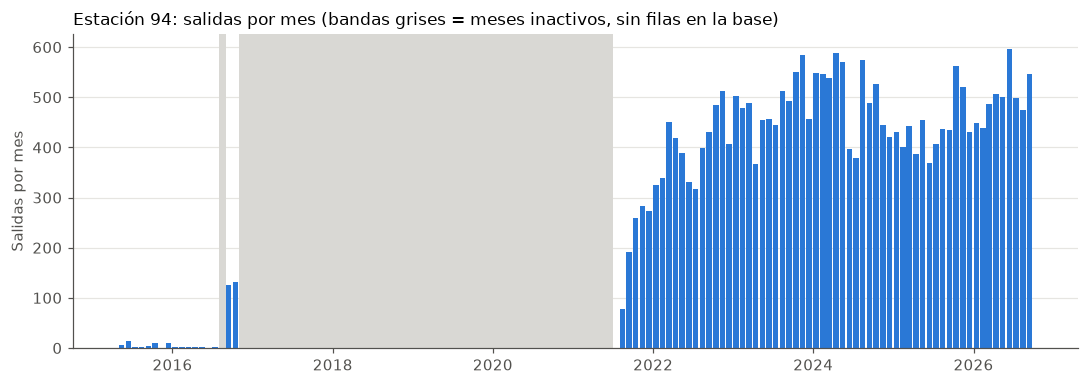

In [6]:
# Estación 94: salidas por mes en toda su vida; los meses inactivos se marcan como bandas
station_id = 94
grid = base[base["station_id"] == station_id]
monthly = grid.groupby(grid["hour_start"].dt.to_period("M"))["departures"].sum()

# Todos los meses entre el primero y el último; los que no están en la grilla son inactivos
all_months = pd.period_range(monthly.index.min(), monthly.index.max(), freq="M")
monthly = monthly.reindex(all_months)
inactive = monthly.isna()

fig, ax = plt.subplots(figsize=(10, 3.6))
x = all_months.to_timestamp()
for month in x[inactive.to_numpy()]:
    ax.axvspan(month, month + pd.offsets.MonthBegin(1), color=INACTIVE, linewidth=0)
ax.bar(x, monthly.fillna(0), width=25, color=SERIES, align="edge")
ax.set_title(
    f"Estación {station_id}: salidas por mes (bandas grises = meses inactivos, sin filas en la base)",
    loc="left",
    fontsize=11,
)
ax.set_ylabel("Salidas por mes")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "1.04-lsg-station-94-lifecycle.png", dpi=150)
plt.show()

**Interpretación**

La estación 94 alterna periodos de operación con periodos largos sin ningún viaje (bandas grises). Esos meses **no aparecen en la base**: no son demanda cero, son periodos en que la estación no estaba operando. Si se rellenaran con 0, el modelo aprendería que esta estación casi no tiene demanda y recomendaría enviar menos bicicletas justo cuando sí opera.

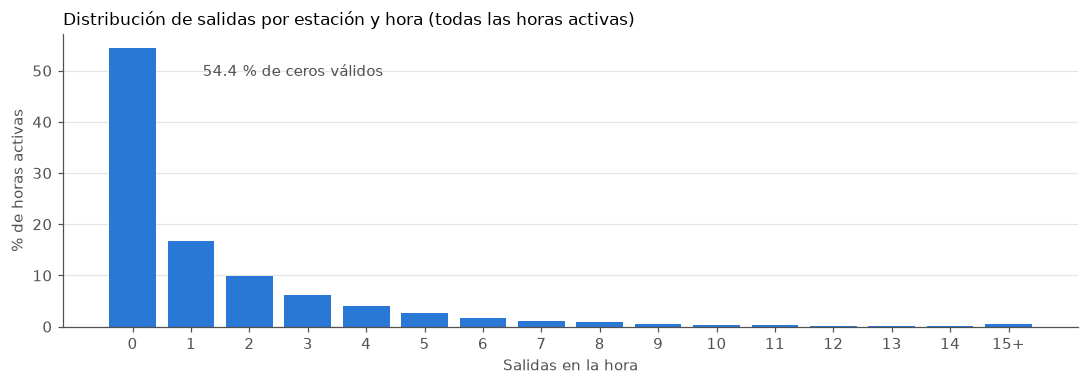

departures,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
% de horas,54.41,16.71,9.95,6.22,4.02,2.65,1.76,1.19,0.82,0.58,0.41,0.3,0.22,0.16,0.12,0.47


In [7]:
# Distribución del target: proporción de horas activas por número de salidas
CAP = 15  # 15 o más se agrupan en la última barra
values = base["departures"].clip(upper=CAP)
share = values.value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(share.index, share.values, width=0.8, color=SERIES)
ax.set_xticks(range(CAP + 1), [str(v) for v in range(CAP)] + [f"{CAP}+"])
ax.set_xlabel("Salidas en la hora")
ax.set_ylabel("% de horas activas")
ax.set_title("Distribución de salidas por estación y hora (todas las horas activas)", loc="left", fontsize=11)
ax.annotate(
    f"{share.loc[0]:.1f} % de ceros válidos",
    xy=(0, share.loc[0]),
    xytext=(1.2, share.loc[0] * 0.9),
    color=MUTED,
    fontsize=10,
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "1.04-lsg-departures-distribution.png", dpi=150)
plt.show()

share.round(2).to_frame("% de horas").T

**Interpretación**

El target está **muy concentrado en valores bajos**: más de la mitad de las horas activas tienen 0 salidas y la frecuencia cae rápidamente al aumentar el conteo, con una cola larga (máximo 207). Implicaciones para fases posteriores:

- Es un problema de **conteos con exceso de ceros**; un baseline razonable debe compararse contra predecir siempre 0 o el promedio histórico de la misma estación y hora.
- Las métricas porcentuales (MAPE) no sirven cuando el valor real es 0; conviene MAE/RMSE o métricas para conteos.
- La cola larga sugiere revisar eventos especiales (celda de horas máximas, más abajo).

### 3.1 Estadísticas del target y sobredispersión

**¿Qué se quiere saber?** Si la variabilidad del target es la que esperaría un modelo de conteos simple, o mucho mayor.

**Fundamento.** El modelo de conteos más simple es la distribución de **Poisson**, que asume que la varianza es igual a la media:

$$\text{Poisson:}\quad \operatorname{Var}(Y) = \mathbb{E}[Y] \qquad\Longrightarrow\qquad D = \frac{\operatorname{Var}(Y)}{\mathbb{E}[Y]} = 1$$

- $Y$: salidas de una estación en una hora.
- $\mathbb{E}[Y]$: promedio de salidas; $\operatorname{Var}(Y)$: varianza.
- $D$: **índice de dispersión**. Se lee: *"cuántas veces más varía el conteo de lo que asumiría Poisson"*.

$D \approx 1$ → Poisson es razonable. $D > 1$ → **sobredispersión**: hay más horas en 0 y más picos de lo que Poisson permite (por ejemplo, por diferencias entre estaciones, horas pico o eventos).

**Ejemplo sencillo:** cuatro horas con salidas 0, 0, 0 y 8 tienen media 2 y varianza (muestral) 16 → $D = 8$: mucho más irregular que cuatro horas con 2, 2, 2 y 2 ($D = 0$).

In [8]:
departures = base["departures"]
target_stats = pd.Series(
    {
        "media": departures.mean(),
        "varianza": departures.var(),
        "indice_dispersion (var/media)": departures.var() / departures.mean(),
        "asimetria (skewness)": departures.skew(),
        "pct_ceros": (departures == 0).mean() * 100,
    }
).round(3)
target_stats.to_frame("todas las horas activas")

,todas las horas activas
media,1.383
varianza,6.358
indice_dispersion (var/media),4.596
asimetria (skewness),4.301
pct_ceros,54.412


In [9]:
# El mismo análisis por estación: ¿la sobredispersión es solo por mezclar estaciones distintas?
per_station = base.groupby("station_id")["departures"].agg(
    media="mean", varianza="var", pct_ceros=lambda x: (x == 0).mean() * 100
)
per_station["indice_dispersion"] = per_station["varianza"] / per_station["media"]
per_station[["media", "pct_ceros", "indice_dispersion"]].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
).round(2)

,media,pct_ceros,indice_dispersion
count,486.00,486.00,486.00
mean,1.06,60.89,2.32
std,1.02,17.33,1.23
min,0.01,25.11,1.12
10%,0.22,37.76,1.35
25%,0.36,46.81,1.51
50%,0.76,60.20,2.00
75%,1.46,75.40,2.70
90%,2.18,83.04,3.56
max,8.10,99.65,15.48


**Interpretación**

- Con todas las horas activas: media ≈ 1.38, varianza ≈ 6.36 → **índice de dispersión ≈ 4.6** y asimetría ≈ 4.3 (cola larga a la derecha).
- **Por estación**, el índice baja pero **todas** las estaciones siguen por encima de 1 (mínimo ≈ 1.12, mediana ≈ 2.0). Parte de la sobredispersión global se explica por **mezclar estaciones con volúmenes muy distintos** (promedio por hora desde ≈ 0.01 hasta ≈ 8.1), pero dentro de cada estación sigue habiendo más variación que la de Poisson: la hora del día, el día de la semana y los eventos importan.
- El porcentaje de ceros también varía mucho entre estaciones (mediana ≈ 60 %, de ≈ 25 % a ≈ 100 %).

**Implicaciones para la Fase 2 (no se deciden aquí):**

1. El modelo necesita información de **estación** y de **calendario**; un único promedio global sería un mal baseline.
2. Si se usa un modelo de conteos, un Poisson simple probablemente se quede corto; conviene contemplar alternativas que admitan sobredispersión (por ejemplo, Binomial Negativa) o modelos de árboles con pérdida para conteos.
3. **Métricas de ML.** El MAPE se indetermina cuando $y_{s,t} = 0$ (más de la mitad de las horas), así que no sirve. Se propone:
   - **MAE**: error medio en salidas por hora, fácil de interpretar.
   - **WAPE** (*Weighted Absolute Percentage Error*), que sí admite ceros porque divide entre el total y no entre cada valor:
     $$\text{WAPE} = \frac{\sum_{s,t} |y_{s,t} - \hat{y}_{s,t}|}{\sum_{s,t} y_{s,t}}$$
     Se lee: *"del total de salidas reales, qué fracción se pronosticó mal"*. Ejemplo: reales 0, 2 y 8 (total 10), pronóstico 1, 2 y 6 → errores 1 + 0 + 2 = 3 → WAPE = 0.3.
   - **RMSE** como complemento: penaliza más los errores grandes (horas pico), lo cual importa porque una hora pico mal pronosticada deja estaciones vacías. Usado solo, puede llevar al modelo a sobreajustar los picos y descuidar las horas valle.
   - **Pérdida de entrenamiento** adecuada a conteos (Poisson o Tweedie) en lugar de MSE, por la sobredispersión y el exceso de ceros.
4. **Métrica de negocio (distinta de la de ML):** lo que importa a la operación es cuántas estaciones quedan vacías o llenas en horas pico y cuántos movimientos de rebalanceo se requieren. El pronóstico es un insumo; su evaluación final debería medirse en esos términos (fuera del alcance de la Fase 1).

### 3.2 Nota de métodos: qué técnicas no se aplican y por qué

El EDA de referencia del curso (notebooks de *Wine Quality*) usa técnicas pensadas para **variables numéricas continuas**. Se evaluaron para este problema y se descartan con justificación:

| Técnica | Por qué no aplica aquí |
|---|---|
| **Regla IQR para atípicos del target** | Con 54 % de ceros, Q1 = 0 y Q3 = 2: el límite superior es 5 y marcaría como "atípicas" al 6 % de las horas, que son simplemente horas pico normales. Los picos se revisan caso por caso (horas máximas). |
| **Mapas de correlación de Pearson/Spearman** | Las variables explicativas disponibles son **categóricas o cíclicas** (estación, hora, día de la semana, mes): una correlación lineal entre las salidas y la hora no tiene sentido (las 23:00 no están "lejos" de las 00:00). Se usan perfiles por grupo (promedio por hora, por día) en su lugar. |
| **Escalamiento o normalización** | No hay modelo todavía; además, cualquier transformación aprendida debe ajustarse solo con datos de entrenamiento después del corte temporal, para evitar fuga de información. |
| **Imputación de faltantes** | La base no tiene faltantes por construcción; los periodos sin operación no se imputan (no se fabrican etiquetas). |
| **Eliminación de picos extremos** | Los picos revisados son demanda real (muchos usuarios distintos, duraciones normales); eliminarlos ocultaría justo la demanda que más importa para el rebalanceo. |

In [10]:
# Horas con más salidas en todo el histórico
top = base.nlargest(10, "departures")[["station_id", "hour_start", "departures", "day_of_week", "hour"]]
top["estacion"] = top["station_id"].map(stations["snapshot_name"])
top["dia"] = top["hour_start"].dt.day_name()
top[["station_id", "estacion", "hour_start", "dia", "departures"]]

,station_id,estacion,hour_start,dia,departures
17249829,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2025-09-20 21:00:00,Saturday,207
17249828,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2025-09-20 20:00:00,Saturday,178
17254532,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-04-04 20:00:00,Saturday,149
17258229,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-09-05 21:00:00,Saturday,141
17254533,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-04-04 21:00:00,Saturday,132
17253188,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-02-07 20:00:00,Saturday,124
17253189,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-02-07 21:00:00,Saturday,121
17258228,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-09-05 20:00:00,Saturday,111
17250837,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2025-11-01 21:00:00,Saturday,109
17253860,194,(GDL-127) Av. Vallarta / Av. de Los Arcos,2026-03-07 20:00:00,Saturday,109


**Interpretación**

Las horas con más salidas del histórico se concentran en la **estación 194 (Av. Vallarta / Av. de Los Arcos)**, en **sábados entre 20:00 y 22:00**. En la hora máxima (2025-09-20 21:00, 207 salidas) se registraron 198 usuarios distintos, con duración mediana de 22 min y destinos variados, y solo 2 viajes con flag: **no parece un error de registro, sino un pico real**, probablemente asociado a un evento o actividad nocturna en la zona (pendiente de confirmar).

**Implicación:** estos picos no deben eliminarse como errores, pero son difíciles de pronosticar sin un calendario de eventos. Se considera en la decisión sobre días atípicos (sección 8) y se contrasta con el análisis de Erik (1.02).

### 3.3 Dependencia temporal: evidencia para el contrato de predicción y el baseline

**Pregunta:** ¿con qué anticipación conviene pronosticar y qué información del pasado predice mejor las salidas?

El contrato define un **corte**: la última hora del día $d$ cuyos datos se usan para pronosticar el día $d+1$. Dos opciones razonables:

| Opción | Corte | Ventaja | Costo |
|---|---|---|---|
| A | 23:59 del día $d$ | Usa todo el día $d$ | El pronóstico solo está listo después de medianoche |
| B | 22:00 del día $d$ | Deja tiempo para planear el rebalanceo nocturno | Pierde las últimas horas del día $d$ |

Para decidir, se miden dos cosas:

1. **Cuánta demanda cae al final del día** (lo que se pierde con un corte anticipado).
2. **Qué tan bien predice cada rezago**, usando predictores ingenuos (sin modelo) evaluados con WAPE y correlación:
   - $\hat{y}_{s,t} = y_{s,t-1}$: la hora anterior. **No está disponible** en un pronóstico de día siguiente; se incluye solo como referencia de cuánto aporta el pasado inmediato.
   - $\hat{y}_{s,t} = y_{s,t-24}$: ayer a la misma hora.
   - $\hat{y}_{s,t} = y_{s,t-48}$: hace dos días.
   - $\hat{y}_{s,t} = y_{s,t-168}$: hace una semana, mismo día y hora.
   - $\hat{y}_{s,t} = \frac{1}{4}\sum_{k=1}^{4} y_{s,t-168k}$: promedio de las últimas 4 semanas, mismo día y hora.

Se evalúa en el periodo reciente (2025-01 a 2026-09). Un rezago solo se usa si la estación estaba activa en esa hora pasada.

In [11]:
# Share of daily departures by hour of day (last 24 months: current network)
recent = base[base["hour_start"] >= "2024-10-01"]
hourly_share = recent.groupby("hour")["departures"].sum() / recent["departures"].sum() * 100
late_day = pd.Series(
    {
        "20:00-23:59": hourly_share.loc[20:23].sum(),
        "22:00-23:59": hourly_share.loc[22:23].sum(),
        "00:00-05:59": hourly_share.loc[0:5].sum(),
    }
).round(2)
late_day.to_frame("% de salidas diarias")

,% de salidas diarias
20:00-23:59,12.84
22:00-23:59,3.59
00:00-05:59,1.46


In [12]:
import numpy as np

# Naive predictors: value of the same station at an earlier hour.
# Lags are looked up by timestamp (not by row position), so hours outside the
# station's active window stay missing instead of borrowing a neighbour's value.
series = base.set_index(["station_id", "hour_start"])["departures"]
evaluation = base.loc[base["hour_start"] >= "2025-01-01", ["station_id", "hour_start", "departures"]]


def lagged(hours):
    keys = pd.MultiIndex.from_arrays(
        [evaluation["station_id"], evaluation["hour_start"] - pd.Timedelta(hours=hours)]
    )
    return series.reindex(keys).to_numpy(dtype=float)


predictors = {
    "hora anterior (t-1, no disponible día siguiente)": lagged(1),
    "ayer, misma hora (t-24)": lagged(24),
    "hace 2 días, misma hora (t-48)": lagged(48),
    "hace 1 semana, misma hora (t-168)": lagged(168),
    # DataFrame.mean skips missing weeks (e.g. a station active for less than 4 weeks)
    "promedio últimas 4 semanas, misma hora": pd.DataFrame(
        np.column_stack([lagged(168 * k) for k in range(1, 5)])
    ).mean(axis=1).to_numpy(),
}

actual = evaluation["departures"].to_numpy(dtype=float)
rows = []
for name, prediction in predictors.items():
    available = ~np.isnan(prediction)
    error = np.abs(actual[available] - prediction[available])
    rows.append(
        {
            "predictor": name,  # display label in Spanish (report language)
            "coverage": available.mean(),
            "MAE": error.mean(),
            "WAPE": error.sum() / actual[available].sum(),
            "correlation": np.corrcoef(actual[available], prediction[available])[0, 1],
        }
    )
naive_scores = pd.DataFrame(rows).set_index("predictor").round(3)
naive_scores

,coverage,MAE,WAPE,correlation
predictor,,,,
"hora anterior (t-1, no disponible día siguiente)",1.000,1.113,0.824,0.663
"ayer, misma hora (t-24)",1.000,1.071,0.792,0.638
"hace 2 días, misma hora (t-48)",0.999,1.157,0.856,0.576
"hace 1 semana, misma hora (t-168)",0.997,0.989,0.730,0.708
"promedio últimas 4 semanas, misma hora",0.997,0.846,0.625,0.790


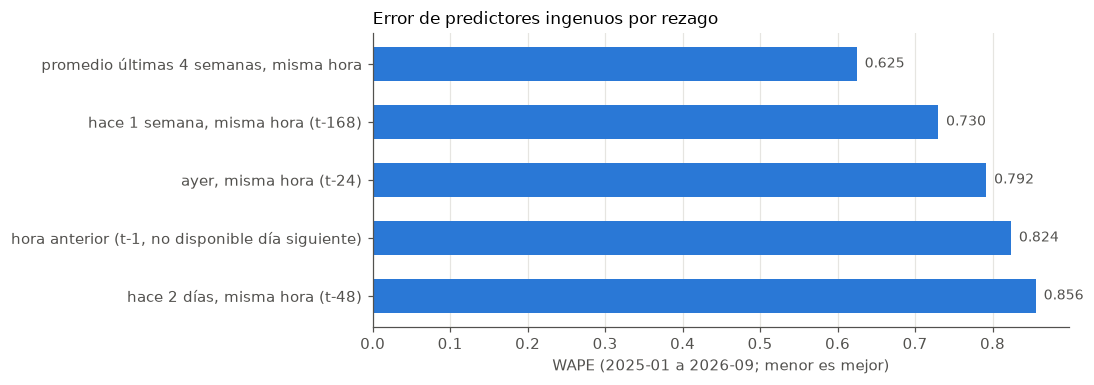

In [13]:
# WAPE by naive predictor (lower is better)
ordered = naive_scores["WAPE"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(ordered.index, ordered.values, height=0.6, color=SERIES)
for y_pos, value in enumerate(ordered.values):
    ax.text(value + 0.01, y_pos, f"{value:.3f}", va="center", color=MUTED, fontsize=9)
ax.set_xlabel("WAPE (2025-01 a 2026-09; menor es mejor)")
ax.set_title("Error de predictores ingenuos por rezago", loc="left", fontsize=11)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "1.04-lsg-naive-predictors-wape.png", dpi=150)
plt.show()

**Interpretación**

- **Demanda al final del día:** entre las 22:00 y las 23:59 ocurre ≈ 3.6 % de las salidas diarias (≈ 12.8 % entre 20:00 y 23:59). Un corte a las 22:00 deja fuera una parte pequeña de la información del día $d$.
- **El patrón semanal pesa más que el pasado inmediato:** "hace una semana, misma hora" (WAPE ≈ 0.73) es mejor que "ayer, misma hora" (≈ 0.79), e incluso que la hora anterior (≈ 0.82), que de todos modos no estaría disponible.
- **El mejor predictor ingenuo es el promedio de las últimas 4 semanas, mismo día y hora** (WAPE ≈ 0.63, correlación ≈ 0.79). Promediar varias semanas suaviza el ruido de una sola.
- Como referencia: predecir siempre 0 da WAPE = 1 y predecir el promedio global da ≈ 1.17; todos los rezagos son mucho mejores.

**Implicaciones:**

1. **Contrato de predicción:** la información más útil (rezagos de 168 h o más) está disponible con cualquiera de los dos cortes. Perder las últimas horas del día $d$ (opción B) tiene un costo bajo: esas horas aportan poca demanda y el rezago de 24 h es el que menos aporta entre los disponibles. → Evidencia para la decisión 0 de la sección 8.
2. **Baseline para la Fase 2:** el promedio de las últimas 4 semanas para la misma estación, día de la semana y hora (WAPE ≈ 0.63) es el punto de referencia que cualquier modelo deberá superar.
3. **Features candidatas:** rezagos semanales (168, 336, … h) y promedios por estación × día × hora calculados **solo con datos anteriores al corte**.

## 4. Patrones temporales (mínimo)

Pendiente. Se completa solo si el notebook 1.01 (José Eduardo) no está disponible a tiempo (plan B).

## 5. Estacionalidad y anomalías (mínimo)

Pendiente. Se completa solo si el notebook 1.02 (Erik) no está disponible a tiempo (plan B).

## 6. Expansión de estaciones (mínimo)

No se requiere plan B: el notebook 1.03 (José Emmanuel) fue integrado. Ver sección 7.3.

## 7. Resultados de los PR del equipo

| Notebook | Autor | PR | Estado |
|---|---|---|---|
| `1.01-jedm-temporal-patterns.ipynb` | José Eduardo De Moraes López | — | Pendiente |
| `1.02-erc-seasonality-anomalies.ipynb` | Erik Román Cortez | — | Pendiente |
| `1.03-jevg-station-expansion.ipynb` | José Emmanuel Vázquez Galán | #3 | Integrado a `main` |

### 7.1 Patrones temporales (1.01)

Pendiente.

### 7.2 Estacionalidad y anomalías (1.02)

Pendiente.

### 7.3 Expansión de estaciones (1.03, José Emmanuel)

**Pregunta:** ¿cómo se comportan las 100 estaciones nuevas de 2026 frente a las consolidadas?

**Método del notebook 1.03:** compara ambos grupos en los mismos meses (2026-01 a 2026-09), normaliza por exposición (salidas por estación-día elegible), estima ceros horarios sin construir la grilla completa y analiza maduración por edad y cohortes. Ventana activa definida **por mes**.

**Hallazgos reportados:** las nuevas registran 9.18 salidas por estación-día frente a 32.53 de las consolidadas (razón 0.282), 78.6 % de horas sin salidas frente a 53.6 %, y una curva de maduración creciente cuyo cruce del 80 % de la referencia ocurre a la edad 4 (con solo 12 estaciones). Recomienda evaluar por separado nuevas y consolidadas y tratar el *cold start*.

**Contraste con `station_hour_base`:** la ventana por mes incluye, en el primer mes de cada estación nueva, las horas anteriores a su apertura. La celda siguiente recalcula los indicadores con la base, que usa bordes por día.

In [14]:
# Recompute the 1.03 comparison with the day-level active window of station_hour_base
period = base[(base["hour_start"] >= "2026-01-01") & (base["hour_start"] < "2026-10-01")]
lifecycle = stations[["is_new_station", "is_retired_by_activity", "first_active_month"]]
period = period.join(lifecycle, on="station_id")

consolidated = (
    ~period["is_new_station"]
    & (period["first_active_month"] < pd.Period("2026-01", freq="M"))
    & ~period["is_retired_by_activity"]
)
period["group"] = np.select([period["is_new_station"], consolidated], ["new", "consolidated"], "other")
period = period[period["group"] != "other"]

groups = period.groupby("group").agg(
    eligible_hours=("departures", "size"),
    departures=("departures", "sum"),
    zero_share=("departures", lambda x: (x == 0).mean() * 100),
)
groups["departures_per_station_day"] = groups["departures"] / (groups["eligible_hours"] / 24)

# Values reported in notebook 1.03 (month-level window), for side-by-side comparison
groups["1.03_eligible_hours"] = pd.Series({"consolidated": 2_407_368, "new": 258_120})
groups["1.03_departures_per_station_day"] = pd.Series({"consolidated": 32.53, "new": 9.18})
groups["1.03_zero_share"] = pd.Series({"consolidated": 53.58, "new": 78.57})
groups.round(2).T

group,consolidated,new
eligible_hours,2407272.00,217536.00
departures,3262622.00,98685.00
zero_share,53.58,74.57
departures_per_station_day,32.53,10.89
1.03_eligible_hours,2407368.00,258120.00
1.03_departures_per_station_day,32.53,9.18
1.03_zero_share,53.58,78.57


In [15]:
# Maturation curve: months since first activity, day-level exposure
new_stations = period[period["group"] == "new"].copy()
months_since_first = new_stations["hour_start"].dt.to_period("M") - new_stations["first_active_month"]
new_stations["age_months"] = months_since_first.apply(lambda offset: offset.n)

maturation = new_stations.groupby("age_months").agg(
    stations=("station_id", "nunique"),
    eligible_hours=("departures", "size"),
    departures=("departures", "sum"),
)
maturation["departures_per_station_day"] = maturation["departures"] / (maturation["eligible_hours"] / 24)
maturation["1.03_departures_per_station_day"] = pd.Series([3.08, 9.83, 10.67, 13.01, 26.25])
maturation.round(2)

,stations,eligible_hours,departures,departures_per_station_day,1.03_departures_per_station_day
age_months,,,,,
0,100,32976,9418,6.85,3.08
1,99,72792,29924,9.87,9.83
2,84,61848,27485,10.67,10.67
3,57,41280,22408,13.03,13.01
4,12,8640,9450,26.25,26.25


**Interpretación**

| Indicador | 1.03 (por mes) | `station_hour_base` (por día) |
|---|---|---|
| Consolidadas: salidas/estación-día | 32.53 | 32.53 (idéntico) |
| Consolidadas: % ceros | 53.58 % | 53.58 % (idéntico) |
| Nuevas: horas elegibles | 258,120 | 217,536 (≈ 40,600 horas previas a la apertura) |
| Nuevas: salidas/estación-día | 9.18 | 10.89 |
| Nuevas: % ceros | 78.57 % | 74.57 % |
| Edad 0 (primer mes) | 3.08 | 6.85 |

- Las consolidadas coinciden exactamente: ambos métodos son consistentes cuando no hay aperturas a mitad de mes.
- Para las nuevas, la ventana por mes **subestima su intensidad y sobrestima sus ceros**, sobre todo en el primer mes: la edad 0 pasa de 3.08 a 6.85 salidas por estación-día. Parte del salto entre la edad 0 y la 1 que parecía maduración era exposición antes de la apertura.
- **Las conclusiones de 1.03 se mantienen:** las nuevas operan con ≈ 1/3 de la intensidad de las consolidadas y más ceros, y la intensidad crece con la edad. El cruce del 80 % a la edad 4 se apoya en una sola cohorte de 12 estaciones (mayo), así que no sirve como umbral general.
- **Evidencia para la decisión 8 (estaciones nuevas):** tratarlas por separado en la evaluación y considerar un historial mínimo para el entrenamiento, con base en la curva de maduración.

## 8. Decisiones

Pendiente. Para cada punto: **decisión · evidencia · justificación · limitación**.

0. Contrato de predicción: hora de corte y horizonte (evidencia: sección 3.3)
1. Granularidad estación × hora
2. `flag_short_same_station`
3. `flag_short_cross_station`
4. Ventana histórica que representa la operación actual
5. Toda la historia o ventana reciente
6. 2020–2021
7. Días atípicos
8. Estaciones nuevas (evidencia: sección 7.3)
9. `snapshot_capacity` como feature
10. Columnas de `processed_v1`

## 9. `processed_v1`

Pendiente.

## 10. MLflow

Pendiente.

## 11. Conclusiones

Pendiente.